In [ ]:
!pip install sdv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.7/204.7 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.5/140.5 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 69.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.5/74.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 202.3/202.3 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 54.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 4.9 MB/s eta 0:00:00


In [ ]:
import pandas as pd

from sdv.single_table import GaussianCopulaSynthesizer
from sdv.metadata import SingleTableMetadata
from sdv.cag import FixedCombinations
from sdv.evaluation.single_table import evaluate_quality, run_diagnostic

# GRID SEARCH
import itertools
from sdmetrics.reports.single_table import QualityReport

# Input

In [ ]:
train_df = pd.read_parquet("/content/train_df_seed42.parquet")
train_df.head() # check if the file has been read correctly

,Patient_ID,Sex,Age,BMI,Smoking_Status,ASA,T2DM,HTN,Dl,IHD,...,Pneumonia,Paralytic_ileus,Kidney_failure,Reintervention,Readmission,LOS_days,Survival_days,Recurrence_free_days,Death,Recurrence
0,223,1,86,31.47,0,3,0,0,1,1,...,0,0,0,0,0,7,1758,545,1,0
1,43,1,75,21.30,2,2,0,0,0,0,...,0,0,0,0,0,39,39,39,1,0
2,214,1,75,25.00,0,3,1,1,1,0,...,0,0,0,0,0,8,797,797,0,0
3,196,1,87,28.13,0,3,1,1,0,0,...,0,0,0,0,0,9,236,77,1,0
4,57,0,78,27.13,0,3,1,1,1,0,...,0,0,0,0,1,6,2066,2066,0,0


In [ ]:
len_real = int(len(train_df)*0.2/0.8+len(train_df)) # length of the real database
len_real

352

# Data distribution analysis
The Gaussian Copula uses the following distributions: beta (default), gamma, gaussian-kde, normal, uniform and truncnorm.

We examine each variable using the `hist()` function.

<Axes: >

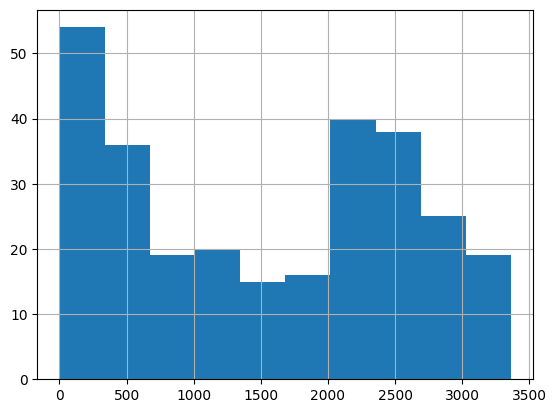

In [ ]:
# Example
train_df['Recurrence_free_days'].hist()
# This is done for each continuous variable

In our case, we choose the following distributions for each variable:

Age: truncnorm

BMI: gamma

Node_ratio: beta

LOS_days: gamma

Survival_days: gaussian_kde

Recurrence_free_days: gaussian_kde


Should a continuous variable have the tail skewed towards the left, so no available distribution is a good option, it needs to be flipped first, before choosing a distribution:



```
max_val = train_df["VARIABLE"].max()
train_df["VARIABLE_flipped"] = max_val - train_df["VARIABLE"]

train_df = train_df.drop(columns=["VARIABLE"])
```



# Data constraints

To make the synthetic data more realistic, we need to specify certain constraints, e.g. if a patient had not had any chemotherapy, they can't have experienced any side-effect from the medication.

In [ ]:
constraints = []

# Cancer staging
constraints.append(FixedCombinations(
    column_names=['T_stage', 'N_stage', 'M_stage', 'TNM_stage']
))

# Chemotherapy
constraints.append(FixedCombinations(column_names=[
        'Adjuvant_CT', 'Early_end_CT', 'CT_toxicity'
    ]))

# Complications
constraints.append(FixedCombinations(column_names=[
    'Anastomosis',
    'Complications',
    'Leak',
    'SSI',
    'Pneumonia',
    'Paralytic_ileus',
    'Kidney_failure'
]))

# Surgery type
constraints.append(FixedCombinations(column_names=[
        'Site', 'Surgery_type'
    ]))

# Metadata

In [ ]:
current_metadata = SingleTableMetadata()
current_metadata.detect_from_dataframe(data=train_df)

# Patient_ID as the ID column
current_metadata.update_column(
    column_name='Patient_ID',
    sdtype='id'
)
current_metadata.set_primary_key('Patient_ID')

# Continuous columns
numerical_columns_for_synth = [
    "Age","Survival_days", "Recurrence_free_days",
    'BMI', 'Node_ratio', 'LOS_days'
]
for col in numerical_columns_for_synth:
  current_metadata.update_column(
      column_name=col,
      sdtype="numerical"
  )

# Categorical columns
for col in train_df.columns.tolist():
  if col != 'Patient_ID' and col not in numerical_columns_for_synth:
    current_metadata.update_column(
        column_name=col,
        sdtype="categorical"
    )

/usr/local/lib/python3.12/dist-packages/sdv/metadata/single_table.py:937: UserWarning: There is an existing primary key 'Patient_ID'. This key will be removed.
  warnings.warn(


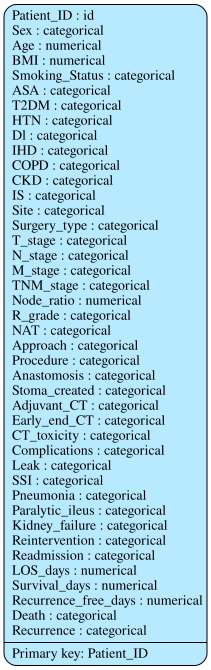

In [ ]:
current_metadata.visualize()

# Synthetic data generation (Demo)

In [ ]:
synthesizer = GaussianCopulaSynthesizer(
    current_metadata,
    enforce_min_max_values=True,
    enforce_rounding=True,
    numerical_distributions={
        'Age': 'truncnorm',
        'BMI':'gamma',
        'Node_ratio':'beta',
        'LOS_days':'gamma',
        'Survival_days':'gaussian_kde',
        'Recurrence_free_days':'gaussian_kde'
    }
)

synthesizer.add_constraints(constraints=constraints)

synthesizer.fit(train_df)

num_rows = len_real # we want the cohort to have the same size as the real dataset
synthetic_data = synthesizer.sample(num_rows=num_rows)

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


If we have flipped variables, we should reverse this now:


```
synthetic_data["VARIABLE"] = max_val - synthetic_data["VARIABLE_flipped"]
synthetic_data = synthetic_data.drop(columns=["VARIABLE_flipped"])
```



In [ ]:
synthetic_data.to_parquet("copula_synth.parquet")

# Grid search: hyperparameter optimization

In [ ]:
def evaluate_config(train_df, val_df_flipped, metadata, numerical_distributions,
                    enforce_min_max, enforce_rounding):
    synthesizer = GaussianCopulaSynthesizer(
        metadata,
        enforce_min_max_values=enforce_min_max,
        enforce_rounding=enforce_rounding,
        numerical_distributions=numerical_distributions,
    )
    synthesizer.add_constraints(constraints=constraints)
    synthesizer.fit(train_df)
    synthetic = synthesizer.sample(num_rows=len(df_input))

    report = QualityReport()
    report.generate(val_df_flipped, synthetic, metadata.to_dict(), verbose=False)
    score = report.get_score()

    return score, synthesizer

In [ ]:
dist_options = ['gamma', 'beta', 'truncnorm']

param_grid = {
    'Age':                   dist_options,
    'BMI':                   dist_options,
    'Node_ratio':            dist_options,
    'LOS_days':              dist_options,
    'enforce_min_max':       [True, False],
    'enforce_rounding':      [True, False],
}

keys   = list(param_grid.keys())
values = list(param_grid.values())
total  = 1
for v in values:
    total *= len(v)

print(f"Grid search: {total} combinations\n")

results      = []
best_score   = -1
best_config  = None
best_synth   = None

for i,combo in enumerate(itertools.product(*values),1):
  params = dict(zip(keys,combo))
  numerical_distributions = {
      'Age':                    params['Age'],
      'BMI':                    params['BMI'],
      'Node_ratio':             params['Node_ratio'],
      'LOS_days':               params['LOS_days'],
      }
  print(f"[{i}/{total}] {params}", end=" → ")
  try:
    score, synth = evaluate_config(train_df, test_df, current_metadata,
                                   numerical_distributions, params['enforce_min_max'],
                                   params['enforce_rounding'])
    results.append({**params, 'score':score})
    print(f"score={score:.4f}")
    if score > best_score:
      best_score = score
      best_config = params
      best_synth = synth
  except Exception as e:
    print(f"FAILED ({e})")
    results.append({**params, 'score':None})

results_df = pd.DataFrame(results).sort_values('score', ascending=False)
results_df.to_csv("copula_grid_results.csv", index=False)
print(f"\nBest score: {best_score:.4f}")
print(f"Best config: {best_config}")

Grid search: 324 combinations

[1/324] {'Age': 'gamma', 'BMI': 'gamma', 'Node_ratio': 'gamma', 'LOS_days': 'gamma', 'enforce_min_max': True, 'enforce_rounding': True} → 

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


score=0.8406
[2/324] {'Age': 'gamma', 'BMI': 'gamma', 'Node_ratio': 'gamma', 'LOS_days': 'gamma', 'enforce_min_max': True, 'enforce_rounding': False} → 

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


score=0.8389
[3/324] {'Age': 'gamma', 'BMI': 'gamma', 'Node_ratio': 'gamma', 'LOS_days': 'gamma', 'enforce_min_max': False, 'enforce_rounding': True} → 

...

score=0.8232
[323/324] {'Age': 'truncnorm', 'BMI': 'truncnorm', 'Node_ratio': 'truncnorm', 'LOS_days': 'truncnorm', 'enforce_min_max': False, 'enforce_rounding': True} → 

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


score=0.8232
[324/324] {'Age': 'truncnorm', 'BMI': 'truncnorm', 'Node_ratio': 'truncnorm', 'LOS_days': 'truncnorm', 'enforce_min_max': False, 'enforce_rounding': False} → 

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


score=0.8232

Best score: 0.8507
Best config: {'Age': 'truncnorm', 'BMI': 'beta', 'Node_ratio': 'gamma', 'LOS_days': 'beta', 'enforce_min_max': True, 'enforce_rounding': True}


# Synthesis with the best configuration

In [ ]:
num_rows = round(len(train_df)*0.2/0.8+len(train_df))
synthetic_data = best_synth.sample(num_rows=num_rows)

synthetic_data.to_parquet("copula_synth_best.parquet", index=False)

In [ ]:
# Save the synthesizer
best_synth.save("copula_best_synthesizer.pkl")
# To load it: synth = GaussianCopulaSynthesizer.load("copula_best_synthesizer.pkl")